In [6]:
%pylab inline
import galsim
import lsst.afw.image as afwImg

Populating the interactive namespace from numpy and matplotlib


# The shape of correlation function

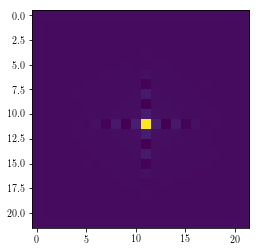

In [2]:
rng = galsim.BaseDeviate(0)
scale=0.168
variance=0.2
ngrid=2048
corFname='./wrkDir/s19/s19-pre/corPre/corGroup-01.fits'
corNoise    =   galsim.getCOSMOSNoise(file_name=corFname,rng=rng,cosmos_scale=scale,variance=variance)
corArray=corNoise.drawImage(scale=scale).array
plt.imshow(corArray)

0.010636136366490974
0.010465067
the estimated variance is: 0.20


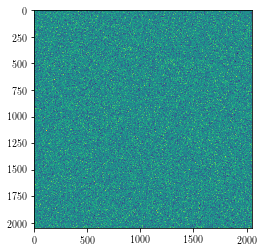

In [3]:
gal_image   =   galsim.ImageF(ngrid,ngrid,scale=scale)
corNoise.applyTo(gal_image)
gal_array=gal_image.array
plt.imshow(gal_array)
var=np.var(gal_array)
cov1=0.
for i in range(2000):
    cov1+=np.average(gal_array[:,i]*gal_array[:,i+1])
print(cov1/2000)
print(corArray[11,12])
print('the estimated variance is: %.2f' %var)

(21, 21)


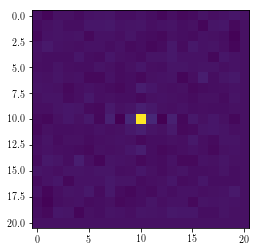

In [4]:
corFname    =   './wrkDir/s19/s19-pre/corPre/corTract-10283.fits'
a=pyfits.getdata(corFname)
print(a.shape)
plt.imshow(a)

# The variance after simulation

In [1]:
expData=pyfits.getdata('wrkDir/s19/s19-1/expDir/image-00000.fits',ext=1)
mskData=pyfits.getdata('wrkDir/s19/s19-1/expDir/image-00000.fits',ext=2)

0.0033938694
0.2405233


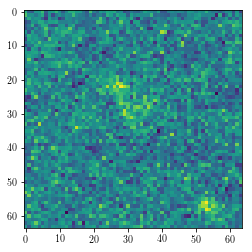

In [17]:
iplot=21
jplot=13
expShow=expData[jplot*64:(jplot+1)*64,iplot*64:(iplot+1)*64]
print(np.var(expShow))
print(np.max(expShow))
plt.imshow(expShow)

In [17]:
varMeas=[]
ntest=10
for i in range(ntest):
    expData=pyfits.getdata('wrkDir/s19/s19-1/expDir/image-%05d.fits' %i,ext=1)
    mskData=pyfits.getdata('wrkDir/s19/s19-1/expDir/image-%05d.fits' %i,ext=2)
    var=np.var(expData[mskData==0])
    varMeas.append(var)
    print(var)

0.003265223
0.0027445653
0.0038408248
0.0026147272
0.0034167762
0.0020136775
0.0043352316
0.0033892517
0.0028583496
0.0028855233


In [18]:
import astropy.io.ascii as ascii
varMeas=np.array(varMeas)
info=ascii.read('wrkDir/s19/s19-pre/info.csv')[0:ntest]
varinput=info['var']
np.average(varMeas/varinput)

0.9462479339629633